In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
url = "https://huggingface.co/datasets/Rodrigopiva/Social_Network_Ads.csv/resolve/main/Social_Network_Ads.csv"

df = pd.read_csv(url)

print(df.head())

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (400, 5)

Column Names:
Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None

Statistical Summary:
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [ ]:
df = df.dropna()

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (400, 5)


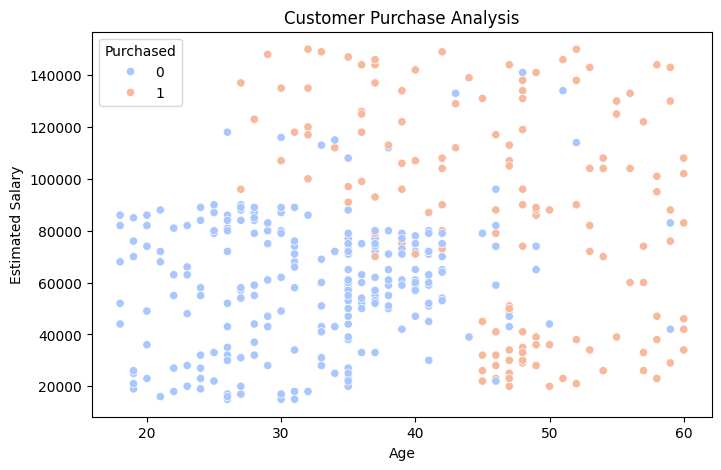

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Age',
    y='EstimatedSalary',
    hue='Purchased',
    palette='coolwarm'
)

plt.title('Customer Purchase Analysis')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')

plt.show()

In [ ]:
X = df[['Age', 'EstimatedSalary']]

y = df['Purchased']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 320
Testing Records: 80


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Purchase': y_test.values,
    'Predicted Purchase': y_pred
})

print(result.head(15))

    Actual Purchase  Predicted Purchase
0                 1                   1
1                 0                   0
2                 0                   0
3                 0                   1
4                 0                   0
5                 1                   1
6                 0                   0
7                 1                   1
8                 0                   1
9                 0                   0
10                0                   0
11                1                   1
12                1                   0
13                0                   1
14                1                   0


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

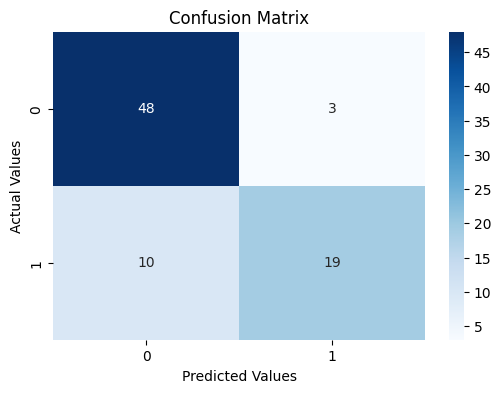

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.title('Confusion Matrix')

plt.show()

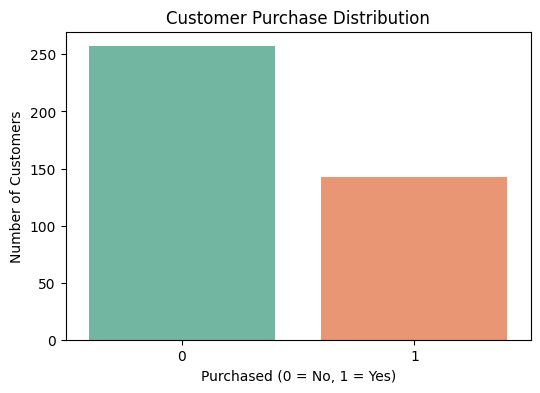

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='Purchased',
    hue='Purchased',
    palette='Set2',
    legend=False
)

plt.title('Customer Purchase Distribution')
plt.xlabel('Purchased (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

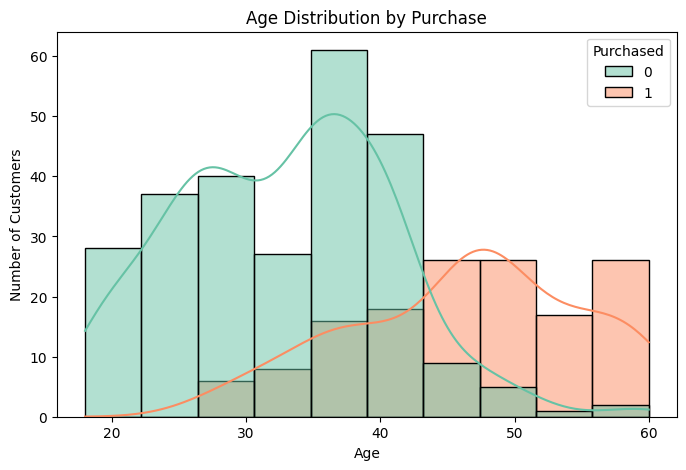

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='Age',
    hue='Purchased',
    kde=True,
    palette='Set2'
)

plt.title('Age Distribution by Purchase')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

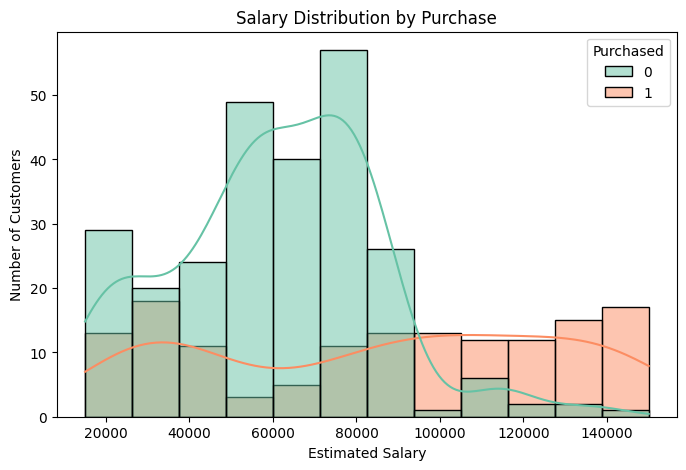

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='EstimatedSalary',
    hue='Purchased',
    kde=True,
    palette='Set2'
)

plt.title('Salary Distribution by Purchase')
plt.xlabel('Estimated Salary')
plt.ylabel('Number of Customers')

plt.show()

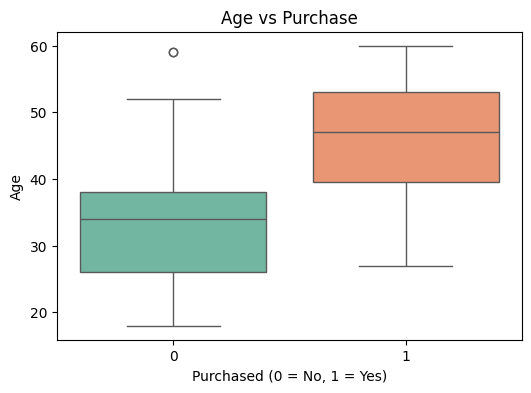

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x='Purchased',
    y='Age',
    hue='Purchased',
    palette='Set2',
    legend=False
)

plt.title('Age vs Purchase')
plt.xlabel('Purchased (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.show()

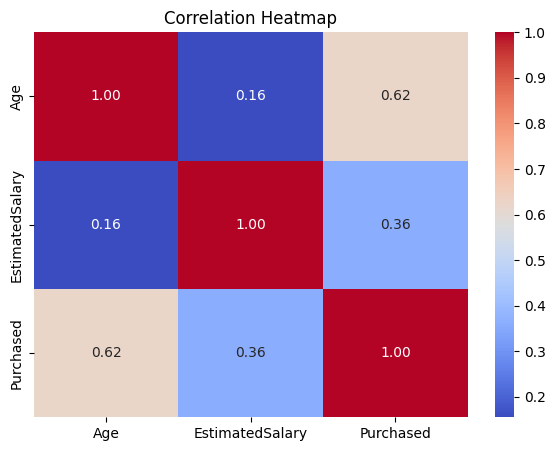

In [ ]:
plt.figure(figsize=(7,5))

sns.heatmap(
    df[['Age', 'EstimatedSalary', 'Purchased']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

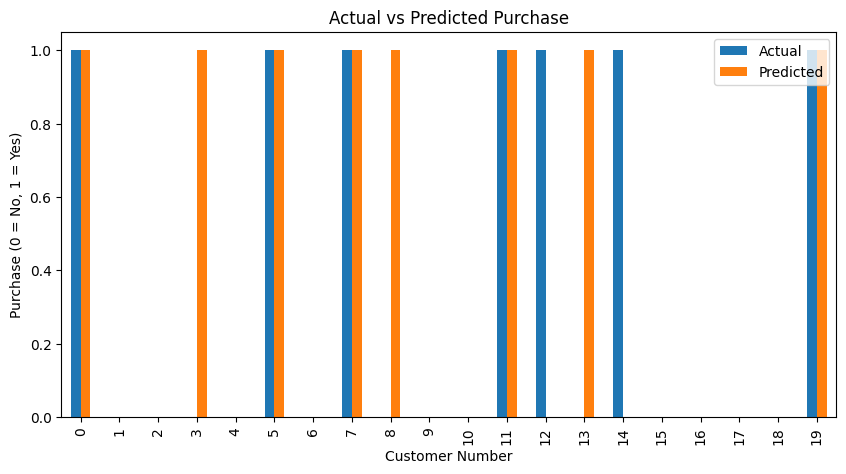

In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison = comparison.reset_index(drop=True)

comparison.head(20).plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Actual vs Predicted Purchase')
plt.xlabel('Customer Number')
plt.ylabel('Purchase (0 = No, 1 = Yes)')

plt.legend()
plt.show()

In [ ]:
new_customer = pd.DataFrame({
    'Age': [35],
    'EstimatedSalary': [60000]
})

new_customer_scaled = scaler.transform(new_customer)

prediction = model.predict(new_customer_scaled)

if prediction[0] == 1:
    print("Customer is likely to purchase the product.")
else:
    print("Customer is unlikely to purchase the product.")

Customer is unlikely to purchase the product.


In [ ]:
print("========== PROJECT SUMMARY ==========")

print("Project: Social Network Ads Purchase Prediction")

print("Algorithm: Logistic Regression")

print("Total Records:", len(df))

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))


print("\nPurchase Distribution:")
print(df['Purchased'].value_counts())

print("\nModel Performance:")
print(classification_report(y_test, y_pred))

print("========== PROJECT COMPLETED ==========")

========== PROJECT SUMMARY ==========
Project: Social Network Ads Purchase Prediction
Algorithm: Logistic Regression
Total Records: 400
Training Records: 320
Testing Records: 80

Purchase Distribution:
Purchased
0    257
1    143
Name: count, dtype: int64

Model Performance:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80

========== PROJECT COMPLETED ==========
